In [1]:
import pandas as pd

# Загрузка данных
df = pd.read_excel(r'C:\Users\User\Desktop\Артур\Artur\Пет-проект аналитика финансов (2).xlsx' , sheet_name='Данные')

# Просмотр первых строк
print("Первые 5 строк данных")
display(df.head())

# Информация о структуре
print("\n Информация о типах данных и пропусках \n")
df.info()

# Статистическое описание (сред, макс, мин и тд)
print("\n Описательная статистика по числовым колонкам")
display(df.describe())

Первые 5 строк данных


,Категория,Дата,Сумма,Тип
0,А,2025-05-09,114900,Актив
1,Т,2025-05-09,22066,Актив
2,Бр.счет,2025-05-09,293593,Инвестиция
3,Вклад,2025-05-09,257790,Подушка
4,Сбер,2025-05-09,27385,Актив



 Информация о типах данных и пропусках 

<class 'pandas.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Категория  112 non-null    str           
 1   Дата       112 non-null    datetime64[us]
 2   Сумма      112 non-null    int64         
 3   Тип        112 non-null    str           
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 3.6 KB

 Описательная статистика по числовым колонкам


,Дата,Сумма
count,112,112.000000
mean,2026-03-12 20:34:17.142857,123394.473214
min,2025-05-09 00:00:00,0.000000
25%,2025-11-09 00:00:00,28837.500000
50%,2026-03-26 00:00:00,69478.500000
75%,2026-07-27 00:00:00,157557.500000
max,2026-10-05 00:00:00,478220.000000
std,NaN,128268.931095


In [2]:
# Группируем по типу актива (аналог сводной таблицы "сумма по типам")
sum_type = df.groupby('Тип')['Сумма'].sum() #()-группировка (создание папок) []-выбор колонки(что считаем)
print("Общая сумма по типам активов \n")
print(sum_type)

# Динамика по месяцам (чтобы видеть тренды)
df['Год-Месяц'] = df['Дата'].dt.to_period('M')

# посчитаем сумму по типам за месяцы
monthly_trend = df.groupby(['Год-Месяц', 'Тип'])['Сумма'].sum().unstack(fill_value=0) #широкий формат, если пусто заполни 0
print("\n Динамика пополнений по месяцам и типам")
display(monthly_trend)


Общая сумма по типам активов 

Тип
Актив         3330380
Инвестиция    8136446
Подушка       2353355
Name: Сумма, dtype: int64

 Динамика пополнений по месяцам и типам


Тип,Актив,Инвестиция,Подушка
Год-Месяц,,,
2025-05,181101,423777,257790
2025-09,229642,538935,152038
2025-10,409723,515294,0
2025-11,231923,528528,150000
2025-12,310836,620752,100740
2026-02,237415,632235,150000
2026-03,268010,647855,151250
2026-04,235530,629555,153305
2026-05,148910,623800,201700


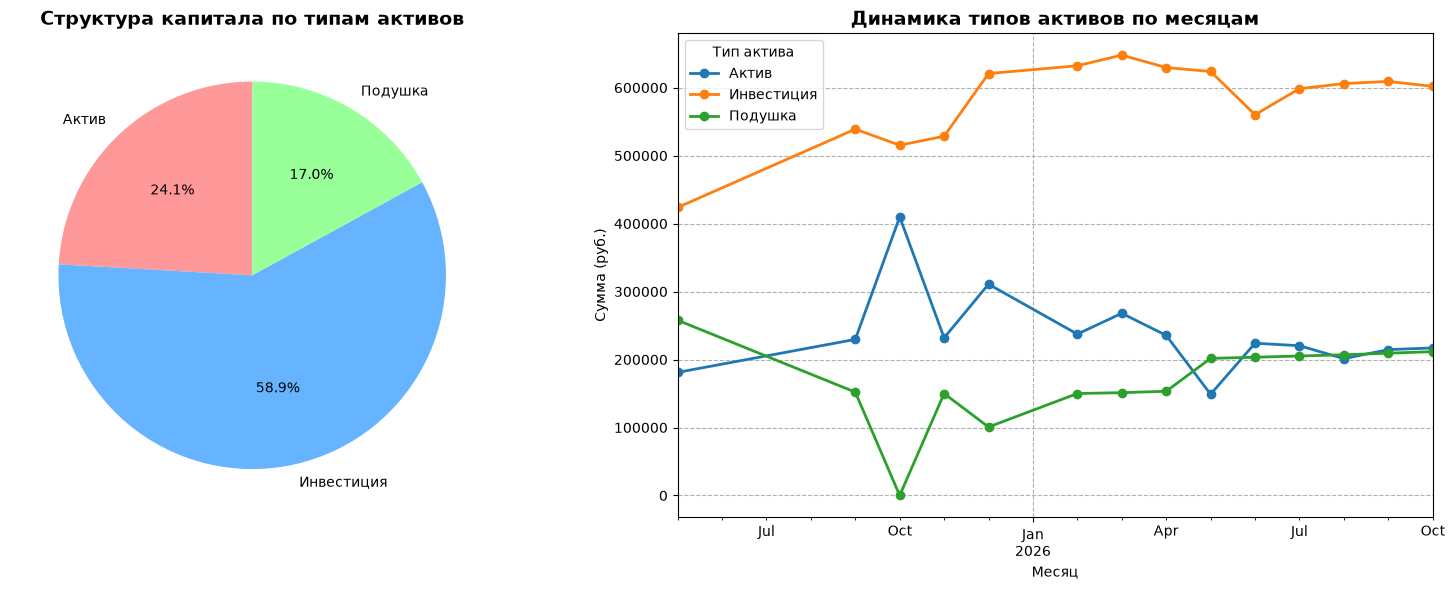

In [3]:
import matplotlib.pyplot as plt

# Создаем фигуру с двумя подграфиками: 1 строка, 2 колонки
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# На левом будет круговая диаграмма
axs[0].pie(
    sum_type.values, #значения сумм
    labels=sum_type.index, #берет названия из индекса сводной таблицы
    autopct='%1.1f%%',
    startangle=90,
    colors=['#FF9999', '#66B3FF', '#99FF99', '#FFCC99']
)
axs[0].set_title('Структура капитала по типам активов', fontsize=14, fontweight='bold')


# Справа будет линейный график
monthly_trend.plot(
    ax=axs[1],          # передаем вторую ось
    marker='o',
    linewidth=2,
    markersize=6
)
axs[1].set_title('Динамика типов активов по месяцам', fontsize=14, fontweight='bold')
axs[1].set_xlabel('Месяц')
axs[1].set_ylabel('Сумма (руб.)')
axs[1].legend(title='Тип актива', loc='best')
axs[1].grid(True, linestyle='--')

# подгон отступов, чтобы подписи не наезжали
plt.tight_layout()
# выводим график
plt.show()



In [4]:
import pandas as pd

# Создаем DataFrame для прогноза
# Предполагаем, что индекс monthly_trend - это даты, а колонка с данными называется 'Сумма'
predict_df = pd.DataFrame({
    'Дата': monthly_trend.index,
    'Сумма': monthly_trend.iloc[:, 0]  # Берем первую колонку с данными
})
#print(monthly_trend.iloc[:, 0])
#print(predict_df.head())


13:57:38 - cmdstanpy - INFO - Chain [1] start processing


Данные готовы. Месяцев для обучения: 14
                   ds        y
Год-Месяц                     
2025-05-01 2025-05-01   862668
2025-09-01 2025-09-01   920615
2025-10-01 2025-10-01   925017
2025-11-01 2025-11-01   910451
2025-12-01 2025-12-01  1032328


13:57:38 - cmdstanpy - INFO - Chain [1] done processing


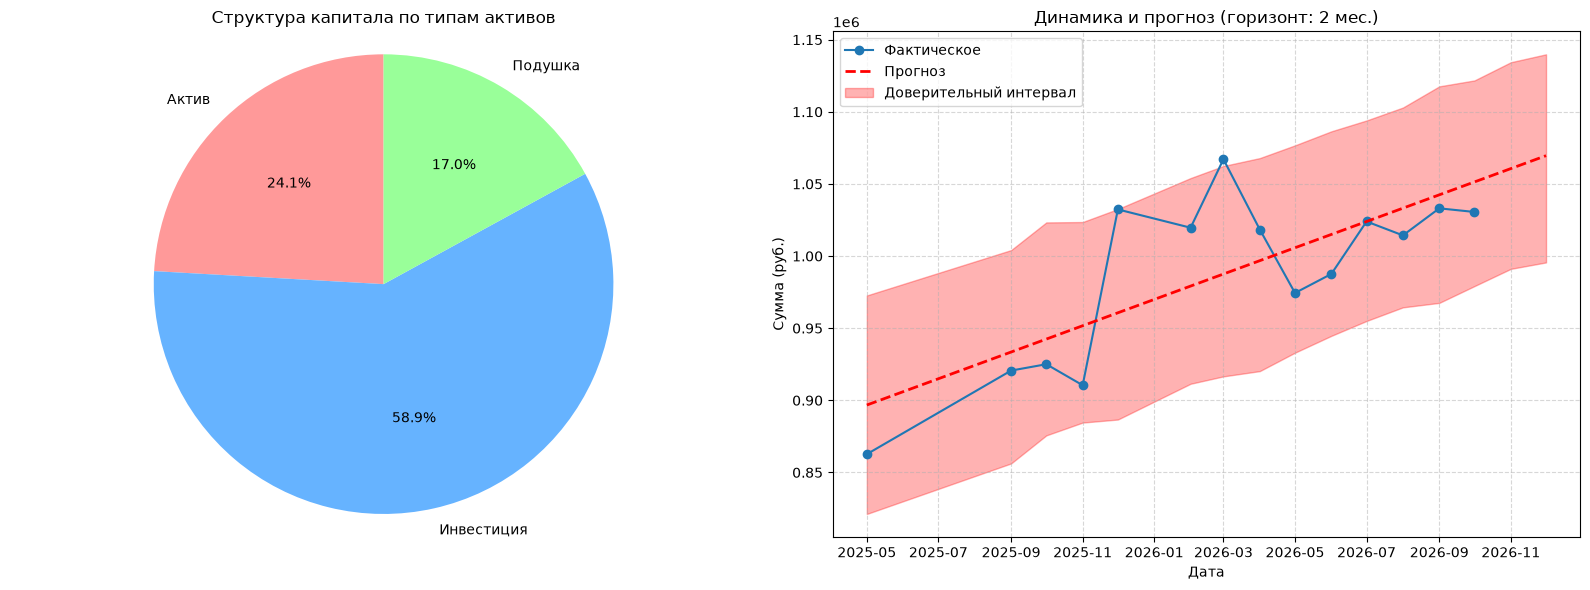


Прогноз на ближайшие месяцы:
         Дата       Прогноз  Нижняя_граница  Верхняя_граница
14 2026-11-01  1.060640e+06   991129.385322     1.134372e+06
15 2026-12-01  1.069589e+06   995576.971136     1.139856e+06

 Прогнозируемая сумма через 2 месяц(-а): 1069589.0


In [11]:
import pandas as pd #библиотека для работы с таблицами
import matplotlib.pyplot as plt #строит графики, визуализация
from prophet import Prophet #строит модели для прогноза

# готовим данные
# Конвертация индекса в Timestamp (если он в формате Period или строки)
if isinstance(monthly_trend.index, pd.PeriodIndex):
    monthly_trend.index = monthly_trend.index.to_timestamp()

monthly_trend = monthly_trend.sort_index()

# делаем df для Prophet
# Так как в месяце уже 1 точка, просто суммируем активы по строкам
predict_df = pd.DataFrame({
    'ds': monthly_trend.index,
    'y': monthly_trend.sum(axis=1)
})

predict_df = predict_df.dropna()

print(f"Данные готовы. Месяцев для обучения: {len(predict_df)}")
print(predict_df.head())

# строим модель и прогноз

periods = 2  # Горизонт прогноза: 2 месяца

model = Prophet(
    yearly_seasonality=False, # учет сезонных колебаний
    daily_seasonality=False, # учет суточных колебаний
    interval_width=0.95, #доверительный интервал
    changepoint_prior_scale=0.05 #контролирует гибкость тренда, делает график более плавным
)

model.fit(predict_df)

future = model.make_future_dataframe(periods=periods, freq='MS')
predict = model.predict(future)

# вывод модели на график, делаем 2 секции 

fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# Левый график (пирог)
if 'sum_type' in globals():
    axs[0].pie(
        sum_type.values,
        labels=sum_type.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=['#FF9999', '#66B3FF', '#99FF99', '#FFCC99']
    )
    axs[0].set_title('Структура капитала по типам активов')
    axs[0].axis('equal')
#else:
  #  axs[0].text(0.5, 0.5, 'Нет данных', ha='center', va='center')
  #  axs[0].set_title('Структура капитала')

# Правый график (динамика)
axs[1].plot(
    predict_df['ds'],
    predict_df['y'],
    marker='o',
    label='Фактическое'
)

axs[1].plot(
    predict['ds'],
    predict['yhat'],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Прогноз'
)

axs[1].fill_between(
    predict['ds'],
    predict['yhat_lower'],
    predict['yhat_upper'],
    color='red',
    alpha=0.3,
    label='Доверительный интервал'
)

axs[1].set_title(f'Динамика и прогноз (горизонт: {periods} мес.)')
axs[1].set_xlabel('Дата')
axs[1].set_ylabel('Сумма (руб.)')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout() # подгон оступов
plt.show()

predict = predict.rename(columns={
    'ds': 'Дата',
    'yhat' : 'Прогноз',
    'yhat_lower': 'Нижняя_граница',
    'yhat_upper': 'Верхняя_граница'
})

# Финальный ответ (прогноз)
print("\nПрогноз на ближайшие месяцы:")
print(predict[['Дата', 'Прогноз', 'Нижняя_граница', 'Верхняя_граница']].tail(periods))
print('\n Прогнозируемая сумма через', periods, 'месяц(-а):', predict['Прогноз'].iloc[-1].round())


_Прогнозируемая сумма через 2 месяца_ - __1 069 589 руб.__

«С вероятностью 95% истинное среднее (реальная сумма по прогнозу) в ноябре 2026 года будет лежать в диапазоне от 0.995 до 1.139 млн рублей. Есть 5% шанс, что сумма выйдет за эти пределы».

Диапазон, в котором лежит истинное среднее всей генеральной совокупности, а не только вашей выборки. Уровень доверия (90 / 95 / 99 %) вы выбираете сами: чем он выше, тем шире рамки.
Считается по t-распределению Стьюдента: M ± t(1−α/2; n−1) · m. Приближение с числом 1,96 годится только для больших выборок, на двадцати наблюдениях оно занижает ширину интервала.
Если интервал узкий — среднее оценено точно; широкий — данных маловато или разброс большой.

>>ПЕСОЧНИЦА

In [6]:
predict_df

,ds,y
Год-Месяц,,
2025-05-01,2025-05-01,862668
2025-09-01,2025-09-01,920615
2025-10-01,2025-10-01,925017
2025-11-01,2025-11-01,910451
2025-12-01,2025-12-01,1032328
2026-02-01,2026-02-01,1019650
2026-03-01,2026-03-01,1067115
2026-04-01,2026-04-01,1018390
2026-05-01,2026-05-01,974410


In [7]:
future

,ds
0,2025-05-01
1,2025-09-01
2,2025-10-01
3,2025-11-01
4,2025-12-01
5,2026-02-01
6,2026-03-01
7,2026-04-01
8,2026-05-01
9,2026-06-01


In [8]:
predict.round(2)

C:\Users\User\AppData\Local\Temp\ipykernel_5396\2056606511.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  predict.round(2)


,Дата,trend,Нижняя_граница,Верхняя_граница,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,Прогноз
0,2025-05-01,896723.99,823206.37,965898.42,896723.99,896723.99,0.0,0.0,0.0,0.0,0.0,0.0,896723.99
1,2025-09-01,933476.27,858739.80,1007824.89,933476.27,933476.27,0.0,0.0,0.0,0.0,0.0,0.0,933476.27
2,2025-10-01,942440.24,873444.93,1015820.35,942440.24,942440.24,0.0,0.0,0.0,0.0,0.0,0.0,942440.24
3,2025-11-01,951703.00,879495.59,1019798.68,951703.00,951703.00,0.0,0.0,0.0,0.0,0.0,0.0,951703.00
4,2025-12-01,960666.97,885730.05,1032083.83,960666.97,960666.97,0.0,0.0,0.0,0.0,0.0,0.0,960666.97
5,2026-02-01,979192.50,904222.81,1046164.09,979192.50,979192.50,0.0,0.0,0.0,0.0,0.0,0.0,979192.50
6,2026-03-01,987551.51,914096.56,1058445.52,987551.51,987551.51,0.0,0.0,0.0,0.0,0.0,0.0,987551.51
7,2026-04-01,996804.40,924396.35,1065015.81,996804.40,996804.40,0.0,0.0,0.0,0.0,0.0,0.0,996804.40
8,2026-05-01,1005753.29,935829.95,1081021.34,1005753.29,1005753.29,0.0,0.0,0.0,0.0,0.0,0.0,1005753.29
9,2026-06-01,1015000.47,942007.35,1086418.23,1015000.47,1015000.47,0.0,0.0,0.0,0.0,0.0,0.0,1015000.47


In [12]:
#predict['прогноз'].round().tail(1)
#list(predict['прогноз']).iloc[-1]
int(predict['Прогноз'].iloc[-1])

1069588